# 02 — Analysis: Q3 and Q4

Các cells tạo các so sánh định lượng và biểu đồ. Chủ sở hữu cần kiểm tra giả định, viết phần giải thích và tự bảo vệ kết luận.

## Q3 — TLD groups and phishing labels

**Chủ sở hữu:** Lê Kiến Quốc — 24127115

**Câu hỏi:** Mối liên hệ giữa TLD và nhãn phishing có thay đổi khi gộp TLD hiếm và so sánh trong các nhóm độ dài URL tương đương không?

**Động lực, người dùng kết quả và quyết định liên quan:** `[chủ sở hữu tự viết]`

Code tách giá trị TLD thiếu khỏi nhóm TLD hiếm. Hai ngưỡng gộp được so sánh. Bảng adjusted rate chuẩn hóa theo phân bố nhóm độ dài URL chung trên các strata hiện diện của từng TLD group. Chủ sở hữu cần chốt ngưỡng, giải thích cách xử lý strata thiếu và viết kết luận.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

starts = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in starts if (p / "environment.yml").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate repository root containing environment.yml.")
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_io import load_raw_csv
from src.url_utils import hostname_from_url

main_raw = load_raw_csv("vn_compphish.csv")
main = main_raw.copy()
main["label_name"] = main["label"].map({0: "benign", 1: "phishing"})
print("Input rows:", len(main))

Input rows: 53116


In [2]:
def tld_groups(frame, min_count):
    values = frame["tld"].fillna("[Missing]").astype(str)
    counts = values.value_counts()
    return values.where(values.eq("[Missing]") | values.map(counts).ge(min_count), "Other")

def length_bins(series, q=5):
    return pd.qcut(series, q=q, labels=False, duplicates="drop").astype("Int64")

def summarize_tld_threshold(frame, min_count, q=5):
    d = frame.copy()
    d["tld_group"] = tld_groups(d, min_count)
    d["length_bin"] = length_bins(d["url_len"], q=q)
    before = len(d)
    d = d.dropna(subset=["label", "tld_group", "length_bin"]).copy()
    overall_weights = d["length_bin"].value_counts(normalize=True)
    cell_rates = d.groupby(["tld_group", "length_bin"], observed=True)["label"].agg(url_n="size", phishing_rate="mean").reset_index()
    rows = []
    for group, part in d.groupby("tld_group", observed=True):
        rates = part.groupby("length_bin", observed=True)["label"].mean()
        weights = overall_weights.reindex(rates.index).dropna()
        adjusted = float(np.average(rates.loc[weights.index], weights=weights))
        rows.append({"tld_group": group, "url_n": len(part), "host_n": part["dom"].nunique(),
                     "raw_phishing_rate": part["label"].mean(), "length_adjusted_rate": adjusted,
                     "length_bins_present": len(rates), "rare_tld_min_n": min_count})
    result = pd.DataFrame(rows).sort_values("url_n", ascending=False).reset_index(drop=True)
    print(f"TLD threshold {min_count}: rows before/after required-field check {before:,} → {len(d):,}")
    return result, cell_rates, d

q3_by_threshold = {}
for threshold in (50, 100, 500):
    summary, cells, data = summarize_tld_threshold(main, threshold, q=5)
    q3_by_threshold[threshold] = {"summary": summary, "cells": cells, "data": data}
print("Threshold 100: TLD groups with row counts, unique hosts, raw rates, and length-standardized rates")
display(q3_by_threshold[100]["summary"].round(4))
print("Threshold 100: TLD × length-group support counts and rates")
display(q3_by_threshold[100]["cells"].sort_values(["tld_group", "length_bin"]).head(40).round(4))

TLD threshold 50: rows before/after required-field check 53,116 → 53,116
TLD threshold 100: rows before/after required-field check 53,116 → 53,116
TLD threshold 500: rows before/after required-field check 53,116 → 53,116
Threshold 100: TLD groups with row counts, unique hosts, raw rates, and length-standardized rates


,tld_group,url_n,host_n,raw_phishing_rate,length_adjusted_rate,length_bins_present,rare_tld_min_n
0,com,21734,12375,0.8636,0.8644,5,100
1,gov.vn,5995,336,0.0000,0.0000,5,100
2,Other,3872,2818,0.5532,0.5976,5,100
3,vn,2995,2521,0.2437,0.3055,5,100
4,xyz,2570,1321,0.9856,0.9876,5,100
5,net,1966,1228,0.7818,0.7965,5,100
6,vip,1502,781,0.9947,0.9958,5,100
7,top,1140,588,0.9825,0.9774,5,100
8,edu.vn,1114,474,0.0099,0.0151,5,100
9,online,849,459,0.9729,0.9039,5,100


Threshold 100: TLD × length-group support counts and rates


,tld_group,length_bin,url_n,phishing_rate
0,Other,0,1312,0.3857
1,Other,1,1037,0.5767
2,Other,2,518,0.6120
3,Other,3,681,0.6858
4,Other,4,324,0.7840
5,[Missing],4,2,1.0000
6,app,0,51,0.7843
7,app,1,40,0.8250
8,app,2,23,1.0000
9,app,3,14,0.9286


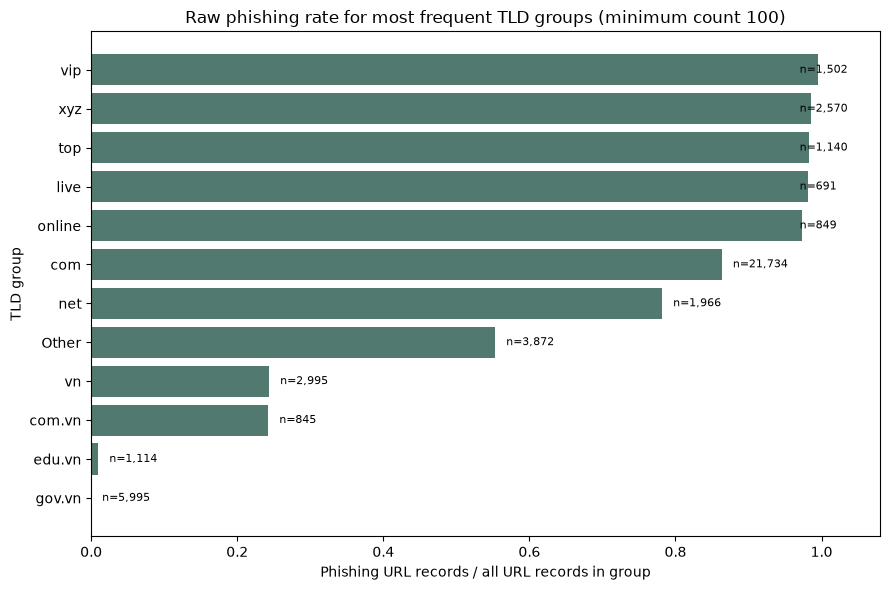

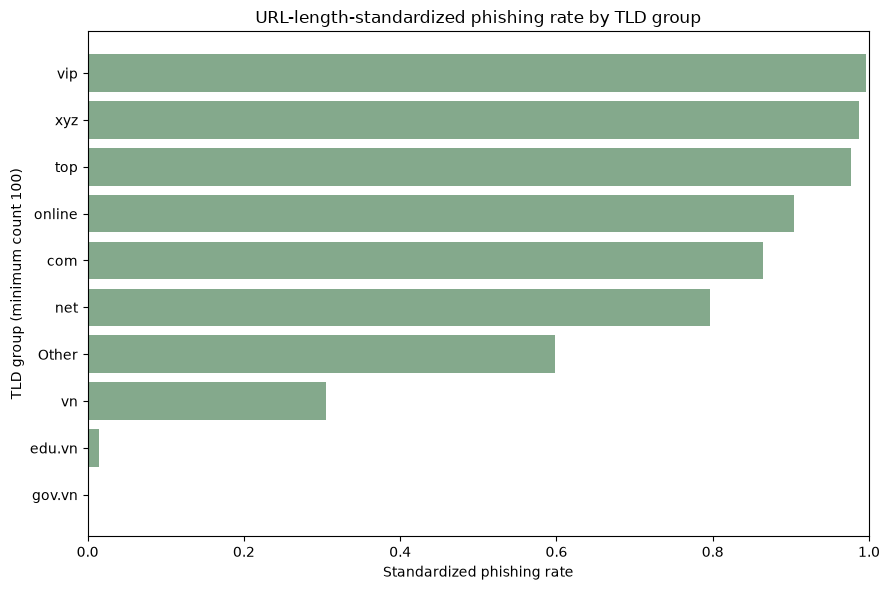

threshold,50,100,500
tld_group,,,
Other,0.5685,0.5976,0.7514
com,0.8644,0.8644,0.8644
gov.vn,0.0000,0.0000,0.0000
net,0.7965,0.7965,0.7965
vip,0.9958,0.9958,0.9958
vn,0.3055,0.3055,0.3055
xyz,0.9876,0.9876,0.9876


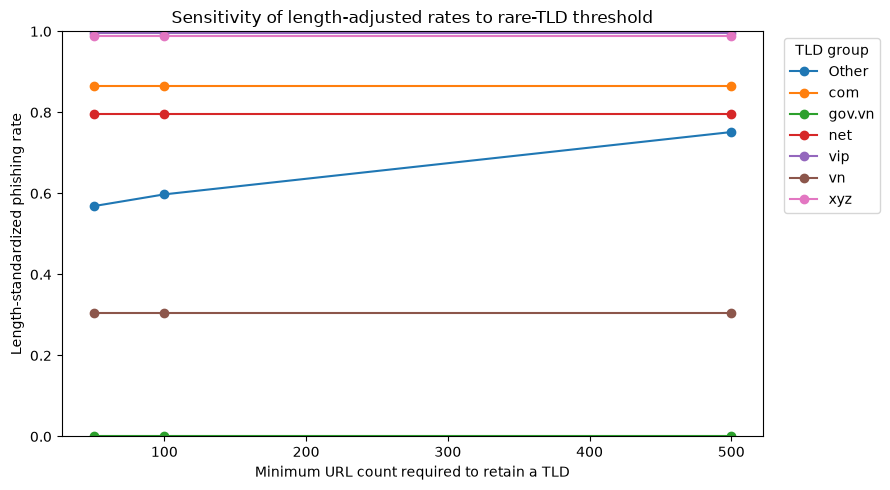

In [3]:
q3_main = q3_by_threshold[100]["summary"]
q3_plot = q3_main.head(12).sort_values("raw_phishing_rate")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(q3_plot["tld_group"], q3_plot["raw_phishing_rate"], color="#52796f")
for y, (_, row) in enumerate(q3_plot.iterrows()):
    ax.text(min(row["raw_phishing_rate"] + .015, .97), y, f"n={int(row['url_n']):,}", va="center", fontsize=8)
ax.set_xlim(0, 1.08)
ax.set_title("Raw phishing rate for most frequent TLD groups (minimum count 100)")
ax.set_xlabel("Phishing URL records / all URL records in group")
ax.set_ylabel("TLD group")
fig.tight_layout()
plt.show()

q3_adjusted = q3_main.head(10).sort_values("length_adjusted_rate")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(q3_adjusted["tld_group"], q3_adjusted["length_adjusted_rate"], color="#84a98c")
ax.set_xlim(0, 1)
ax.set_title("URL-length-standardized phishing rate by TLD group")
ax.set_xlabel("Standardized phishing rate")
ax.set_ylabel("TLD group (minimum count 100)")
fig.tight_layout()
plt.show()

focus = [g for g in q3_main.loc[~q3_main["tld_group"].isin(["Other", "[Missing]", "[Missing]"]), "tld_group"].head(6)] + ["Other"]
robust_rows = []
for threshold, bundle in q3_by_threshold.items():
    s = bundle["summary"].set_index("tld_group")
    for group in focus:
        if group in s.index:
            robust_rows.append({"threshold": threshold, "tld_group": group, "url_n": s.loc[group, "url_n"], "adjusted_rate": s.loc[group, "length_adjusted_rate"]})
q3_robust = pd.DataFrame(robust_rows)
display(q3_robust.pivot(index="tld_group", columns="threshold", values="adjusted_rate").round(4))
fig, ax = plt.subplots(figsize=(9, 5))
for group, part in q3_robust.groupby("tld_group"):
    ax.plot(part["threshold"], part["adjusted_rate"], marker="o", label=group)
ax.set_title("Sensitivity of length-adjusted rates to rare-TLD threshold")
ax.set_xlabel("Minimum URL count required to retain a TLD")
ax.set_ylabel("Length-standardized phishing rate")
ax.set_ylim(0, 1)
ax.legend(title="TLD group", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

### Q3 — nhóm hoàn thiện

- Vì sao chọn ngưỡng/strata và cách xử lý TLD thiếu: `[tự viết]`
- Động lực, người dùng kết quả và quyết định liên quan: `[tự viết]`
- Trả lời Q3 bằng số liệu từ bảng/biểu đồ: `[tự viết]`
- Kết quả robustness và giới hạn nhóm nhỏ: `[tự viết]`

## Q4 — Repeated-host patterns

**Chủ sở hữu:** Lê Kiến Quốc — 24127115

**Câu hỏi:** Hostname xuất hiện nhiều lần có tỷ lệ URL phishing khác hostname chỉ xuất hiện một lần không, và kết quả thay đổi thế nào theo nhóm TLD?

**Động lực, người dùng kết quả và quyết định liên quan:** `[chủ sở hữu tự viết]`

Hostname được trích trực tiếp từ `url`; `dom` được giữ làm phép so sánh ở grain domain vì hai trường này không tương đương trong mọi dòng. Mỗi hostname là một đơn vị cho so sánh trung bình host-level. Bảng cũng báo cáo URL counts và URL-weighted rates riêng. Khoảng bất định của chênh lệch host-level được bootstrap bằng cách lấy mẫu hostname có hoàn lại.

In [4]:
host_rows = main.dropna(subset=["url", "label"]).copy()
host_rows["hostname"] = host_rows["url"].map(hostname_from_url)
q4_before = len(host_rows)
host_rows = host_rows.dropna(subset=["hostname"]).copy()
hosts = host_rows.groupby("hostname", as_index=False).agg(
    url_n=("label", "size"), phishing_url_n=("label", "sum"),
    host_phishing_rate=("label", "mean"), tld=("tld", "first")
)
hosts["repeat_group"] = np.where(hosts["url_n"].gt(1), "repeated", "singleton")
hosts["tld_group"] = tld_groups(hosts, min_count=100)

# The supplied `dom` field is a broader grouping in some rows; keep it as a separately named sensitivity.
domain_rows = main.dropna(subset=["dom", "label"]).groupby("dom", as_index=False).agg(
    url_n=("label", "size"), phishing_url_n=("label", "sum"),
    domain_phishing_rate=("label", "mean"), tld=("tld", "first")
)
domain_rows["repeat_group"] = np.where(domain_rows["url_n"].gt(1), "repeated", "singleton")
print(f"Q4 URL rows before/after host-field check: {len(main):,} → {len(host_rows):,}")
print(f"URL rows → distinct URL-derived hostnames: {len(host_rows):,} → {len(hosts):,}")
print(f"URL rows → distinct `dom` values for sensitivity: {len(main):,} → {len(domain_rows):,}")
print("URL-derived hostname groups by repetition status:")
display(hosts.groupby("repeat_group").agg(host_n=("hostname", "size"), url_n=("url_n", "sum"),
                                          mean_host_phishing_rate=("host_phishing_rate", "mean"),
                                          url_weighted_phishing_rate=("phishing_url_n", "sum")).assign(
    url_weighted_phishing_rate=lambda x: x["url_weighted_phishing_rate"] / x["url_n"]
).round(4))
print("Hostname × TLD group × repetition status:")
display(hosts.groupby(["tld_group", "repeat_group"], observed=True).agg(
    host_n=("hostname", "size"), url_n=("url_n", "sum"), mean_host_phishing_rate=("host_phishing_rate", "mean"),
    url_weighted_phishing_rate=("phishing_url_n", "sum")
).assign(url_weighted_phishing_rate=lambda x: x["url_weighted_phishing_rate"] / x["url_n"]).round(4).head(50))

Q4 URL rows before/after host-field check: 53,116 → 53,116
URL rows → distinct URL-derived hostnames: 53,116 → 53,042
URL rows → distinct `dom` values for sensitivity: 53,116 → 28,647
URL-derived hostname groups by repetition status:


,host_n,url_n,mean_host_phishing_rate,url_weighted_phishing_rate
repeat_group,,,,
repeated,45,119,0.4815,0.5966
singleton,52997,52997,0.6913,0.6913


Hostname × TLD group × repetition status:


host_n  url_n  mean_host_phishing_rate  \
tld_group repeat_group                                           
Other     repeated          11     42                   1.0000   
          singleton       3830   3830                   0.5483   
[Missing] singleton          2      2                   1.0000   
app       repeated           2      9                   1.0000   
          singleton        155    155                   0.8774   
asia      singleton        122    122                   0.8770   
biz       singleton        130    130                   0.8846   
cc        singleton        523    523                   0.9369   
cfd       singleton        170    170                   0.9882   
click     singleton        165    165                   0.9818   
club      singleton        630    630                   0.9952   
cn        singleton        414    414                   0.8889   
co        singleton        334    334                   0.8563   
co.uk     singleton        200    200                   0.5000   
com       repeated           6     13                   0.7778   
          singleton      21721  21721                   0.8636   
com.vn    singleton        845    845                   0.2426   
de        singleton        552    552                   0.7391   
edu.vn    singleton       1114   1114                   0.0099   
fun       singleton        299    299                   0.9900   
gov.vn    repeated          21     43                   0.0000   
          singleton       5952   5952                   0.0000   
icu       singleton        115    115                   0.9652   
in        singleton        130    130                   0.6538   
info      singleton        431    431                   0.9420   
io        repeated           1      2                   1.0000   
          singleton        283    283                   0.6325   
life      singleton        177    177                   0.9774   
live      singleton        691    691                   0.9812   
me        singleton        502    502                   0.9382   
net       singleton       1966   1966                   0.7818   
online    singleton        849    849                   0.9729   
org       repeated           1      4                   1.0000   
          singleton        571    571                   0.6007   
pro       singleton        287    287                   0.9547   
ru        singleton        249    249                   0.0482   
shop      repeated           1      2                   1.0000   
          singleton        264    264                   0.9318   
site      singleton        346    346                   0.9480   
store     singleton        152    152                   0.9605   
tk        singleton        117    117                   1.0000   
top       singleton       1140   1140                   0.9825   
us        singleton        171    171                   0.9064   
vin       singleton        136    136                   1.0000   
vip       singleton       1502   1502                   0.9947   
vn        repeated           1      2                   0.0000   
          singleton       2993   2993                   0.2439   
win       singleton        199    199                   0.9899   
xyz       repeated           1      2                   1.0000   
          singleton       2568   2568                   0.9856   

                        url_weighted_phishing_rate  
tld_group repeat_group                              
Other     repeated                          1.0000  
          singleton                         0.5483  
[Missing] singleton                         1.0000  
app       repeated                          1.0000  
          singleton                         0.8774  
asia      singleton                         0.8770  
biz       singleton                         0.8846  
cc        singleton                         0.9369  
cfd       singleton                         0.9882  
click   

In [5]:
def host_bootstrap_difference(host_frame, outcome, group_col="repeat_group", positive="repeated", negative="singleton", n_boot=2000, seed=41):
    groups = {name: host_frame.loc[host_frame[group_col].eq(name), outcome].dropna().to_numpy() for name in (positive, negative)}
    estimate = float(groups[positive].mean() - groups[negative].mean())
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)
    for i in range(n_boot):
        pos = rng.choice(groups[positive], size=len(groups[positive]), replace=True).mean()
        neg = rng.choice(groups[negative], size=len(groups[negative]), replace=True).mean()
        boot[i] = pos - neg
    low, high = np.quantile(boot, [.025, .975])
    return {"estimate": estimate, "ci_low": float(low), "ci_high": float(high),
            "repeated_hosts": len(groups[positive]), "singleton_hosts": len(groups[negative])}

q4_effect = host_bootstrap_difference(hosts, "host_phishing_rate")
q4_domain_effect = host_bootstrap_difference(domain_rows, "domain_phishing_rate", seed=42)
q4_effect_table = pd.DataFrame([{"unit": "URL-derived hostname", **q4_effect}, {"unit": "dom-field domain grouping", **q4_domain_effect}])
display(q4_effect_table.round(4))
q4_summary = hosts.groupby("repeat_group").agg(host_n=("hostname", "size"), url_n=("url_n", "sum"),
    mean_host_rate=("host_phishing_rate", "mean"), url_phishing_rate=("phishing_url_n", "sum")).reset_index()
q4_summary["url_phishing_rate"] = q4_summary["url_phishing_rate"] / q4_summary["url_n"]
display(q4_summary.round(4))
print("Domain-field sensitivity summary:")
display(domain_rows.groupby("repeat_group").agg(domain_n=("dom", "size"), url_n=("url_n", "sum"), mean_domain_phishing_rate=("domain_phishing_rate", "mean"), url_phishing_n=("phishing_url_n", "sum")).assign(url_weighted_phishing_rate=lambda x: x["url_phishing_n"] / x["url_n"]).round(4))

,unit,estimate,ci_low,ci_high,repeated_hosts,singleton_hosts
0,URL-derived hostname,-0.2098,-0.3574,-0.069,45,52997
1,dom-field domain grouping,0.8304,0.8235,0.837,17056,11591


,repeat_group,host_n,url_n,mean_host_rate,url_phishing_rate
0,repeated,45,119,0.4815,0.5966
1,singleton,52997,52997,0.6913,0.6913


Domain-field sensitivity summary:


,domain_n,url_n,mean_domain_phishing_rate,url_phishing_n,url_weighted_phishing_rate
repeat_group,,,,,
repeated,17056,41525,0.9882,34876,0.8399
singleton,11591,11591,0.1579,1830,0.1579


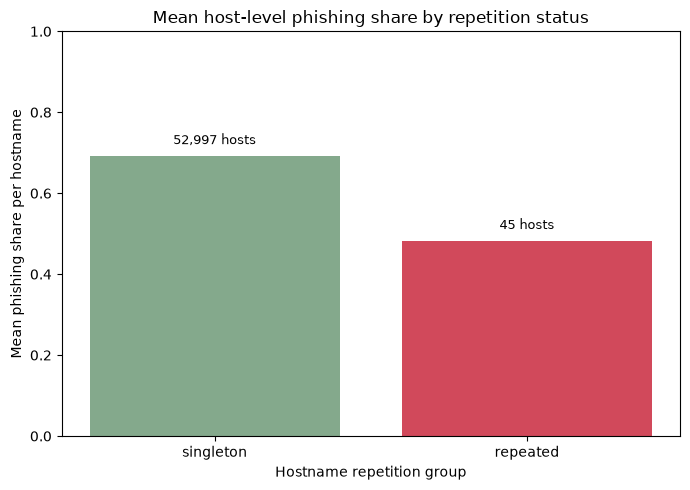

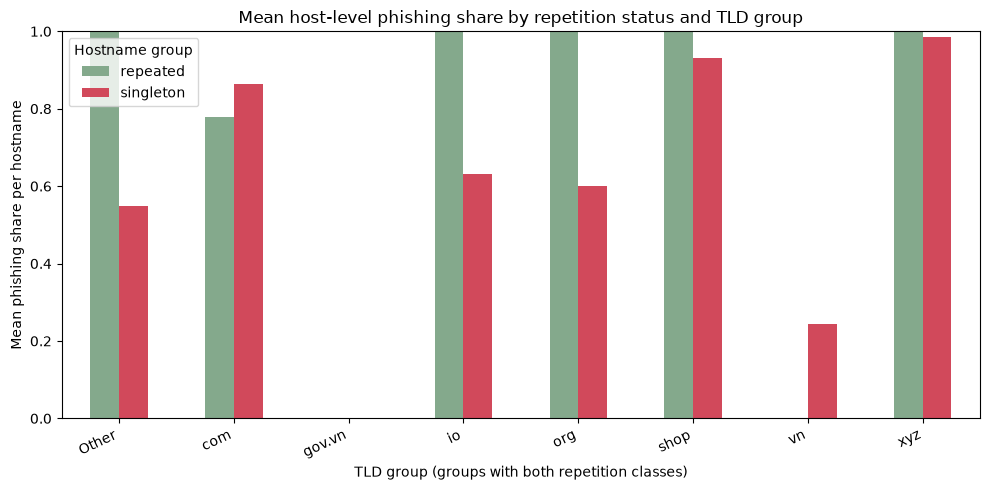

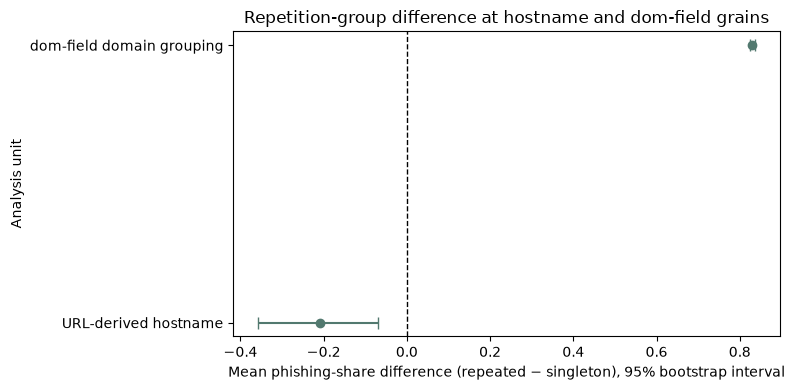

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
order = ["singleton", "repeated"]
means = hosts.groupby("repeat_group")["host_phishing_rate"].mean().reindex(order)
ax.bar(order, means, color=["#84a98c", "#d1495b"])
ax.set_ylim(0, 1)
ax.set_title("Mean host-level phishing share by repetition status")
ax.set_xlabel("Hostname repetition group")
ax.set_ylabel("Mean phishing share per hostname")
for i, group in enumerate(order):
    n = int(hosts["repeat_group"].eq(group).sum())
    ax.text(i, min(means[group] + .03, .97), f"{n:,} hosts", ha="center", fontsize=9)
fig.tight_layout()
plt.show()

q4_tld = hosts.groupby(["tld_group", "repeat_group"], observed=True)["host_phishing_rate"].agg(["mean", "size"]).reset_index()
common_tlds = q4_tld.groupby("tld_group")["repeat_group"].nunique()
common_tlds = common_tlds[common_tlds.eq(2)].index
plot_tlds = q4_tld[q4_tld["tld_group"].isin(common_tlds)].groupby("tld_group")["size"].sum().nlargest(8).index
q4_plot = q4_tld[q4_tld["tld_group"].isin(plot_tlds)]
q4_wide = q4_plot.pivot(index="tld_group", columns="repeat_group", values="mean")
ax = q4_wide.plot(kind="bar", figsize=(10, 5), color=["#84a98c", "#d1495b"])
ax.set_ylim(0, 1)
ax.set_title("Mean host-level phishing share by repetition status and TLD group")
ax.set_xlabel("TLD group (groups with both repetition classes)")
ax.set_ylabel("Mean phishing share per hostname")
ax.legend(title="Hostname group")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for i, row in q4_effect_table.iterrows():
    ax.errorbar(row["estimate"], i, xerr=[[row["estimate"] - row["ci_low"]], [row["ci_high"] - row["estimate"]]], fmt="o", capsize=4, color="#52796f")
ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.set_yticks(range(len(q4_effect_table)), q4_effect_table["unit"])
ax.set_title("Repetition-group difference at hostname and dom-field grains")
ax.set_xlabel("Mean phishing-share difference (repeated − singleton), 95% bootstrap interval")
ax.set_ylabel("Analysis unit")
fig.tight_layout()
plt.show()

### Q4 — nhóm hoàn thiện

- Định nghĩa hostname, repeated/singleton và đơn vị phân tích: `[tự viết]`
- Động lực, người dùng kết quả và quyết định liên quan: `[tự viết]`
- Trả lời Q4 bằng kết quả host-level và URL-weighted: `[tự viết]`
- Diễn giải phân tầng TLD, khoảng bất định và hạn chế: `[tự viết]`